# 非平衡化学の検証計算

固定密度の単一セルで、恒星電離光・遠紫外線の点灯と消灯に対する温度、化学組成、加熱・冷却率の応答を描きます。同じ条件での平衡・非平衡の冷却率と、両モードのエネルギー更新にかかる時間を比較します。水素の再結合と時間刻みの数値検証も含みます。再計算時の非平衡モードには既定の温度係数の表引きを使います。

高温ガスの等積冷却では、温度と冷却率の時間変化を示します。恒星電離光を消した後の酸素輝線の応答も確認します。

既定の出力先でデータが不足していれば、最初のコードセルでテスト計算を実行します。ライブラリの変更を反映して再計算するには `rerun = True`、保存済みの結果を使うには `data_dir` を変更してください。計算条件は [README](../README.md#非平衡化学の検証計算と描画) にあります。

In [1]:
%matplotlib inline

import subprocess
import sys
from math import log
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

cwd = Path.cwd()
repo_root = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "test" / "noneq" / "NonEquilibriumTest.c").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("EQCLib のリポジトリ内からノートブックを実行してください。")

default_data_dir = (repo_root / "test" / "out" / "noneq").resolve()
data_dir = default_data_dir
rerun = False

plot_dir = str(repo_root / "plot")
if plot_dir not in sys.path:
    sys.path.insert(0, plot_dir)

from plot_noneq import (
    FUV_PANELS, IONIZING_PANELS, benchmark_timings, plot_benchmark, plot_cooling_comparison,
    plot_hot_cooling, plot_oxygen_after_switch, plot_pulse, plot_validation, read_csv,
)
from plot_style import PLOT_STYLE

data_dir = data_dir.resolve()
filenames = ("evolution.csv", "recombination.csv", "convergence.csv")
benchmark_path = data_dir / "benchmark.csv"
hot_paths = tuple(data_dir / name for name in ("hot_cooling.csv", "oxygen_after_switch.csv"))


def load_hot_data():
    if not all(path.is_file() for path in hot_paths):
        return None
    data = tuple(read_csv(path) for path in hot_paths)
    # In older outputs, cie_bridge referred to the linear CIE calculation.
    if any("cie_linear" not in rows["method"] or "cie_bridge" not in rows["method"] for rows in data):
        return None
    return tuple(rows[rows["method"] == "cie_bridge"] for rows in data)


hot_data = None if rerun else load_hot_data()
targets = []
if data_dir == default_data_dir:
    if rerun or not all((data_dir / name).is_file() for name in filenames):
        targets.append("noneq")
    else:
        with (data_dir / "evolution.csv").open() as csv_file:
            if "eq_native_L_tot" not in csv_file.readline().strip().split(","):
                targets.append("noneq")
    if rerun or not benchmark_path.is_file():
        targets.append("noneq-benchmark")
    if hot_data is None:
        targets.append("noneq-hot")

if targets:
    completed = subprocess.run(
        ["make", "-j1", "-C", "test", *targets],
        cwd=repo_root,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )
    if completed.returncode:
        print(completed.stdout)
        completed.check_returncode()

missing = [name for name in filenames if not (data_dir / name).is_file()]
if missing:
    raise FileNotFoundError(f"{data_dir} に {', '.join(missing)} がありません。data_dir を確認してください。")

evolution, recombination, convergence = (read_csv(data_dir / name) for name in filenames)
benchmark = read_csv(benchmark_path) if benchmark_path.is_file() else None
if rerun or "noneq-hot" in targets:
    hot_data = load_hot_data()
hot_labels = {"hot_1e6": "10⁶ K", "hot_1e7": "10⁷ K"}
hot_missing = "現行モデルの高温冷却データがありません。既定の data_dir で make -C test noneq-hot を実行してください。"
benchmark_labels = {"ionizing": "電離光あり", "recombining": "消灯後の再結合", "fuv": "遠紫外線あり"}
shown_dir = data_dir.relative_to(repo_root) if repo_root in data_dir.parents else data_dir
print(f"計算結果 {shown_dir}")

計算結果 test/out/noneq


## 恒星電離光のオン・オフ

水素核数密度は 10 cm⁻³、初期温度は 8,000 K です。約16年間の照射中と消灯後100万年までの温度、H・He・C・O の電離状態、電子分率、[C II] 158 µm・[O II]・[O III] の冷却を表示します。消灯直後の [C II] と [O II] は、二価イオンから一価イオンへの再結合でいったん強まり、その後弱まります。

左の横軸は点灯から、右の横軸は消灯からの経過時間です。レートは正の値を描きます。切り替えの前後と符号付きのレートは `evolution.csv` で確認できます。

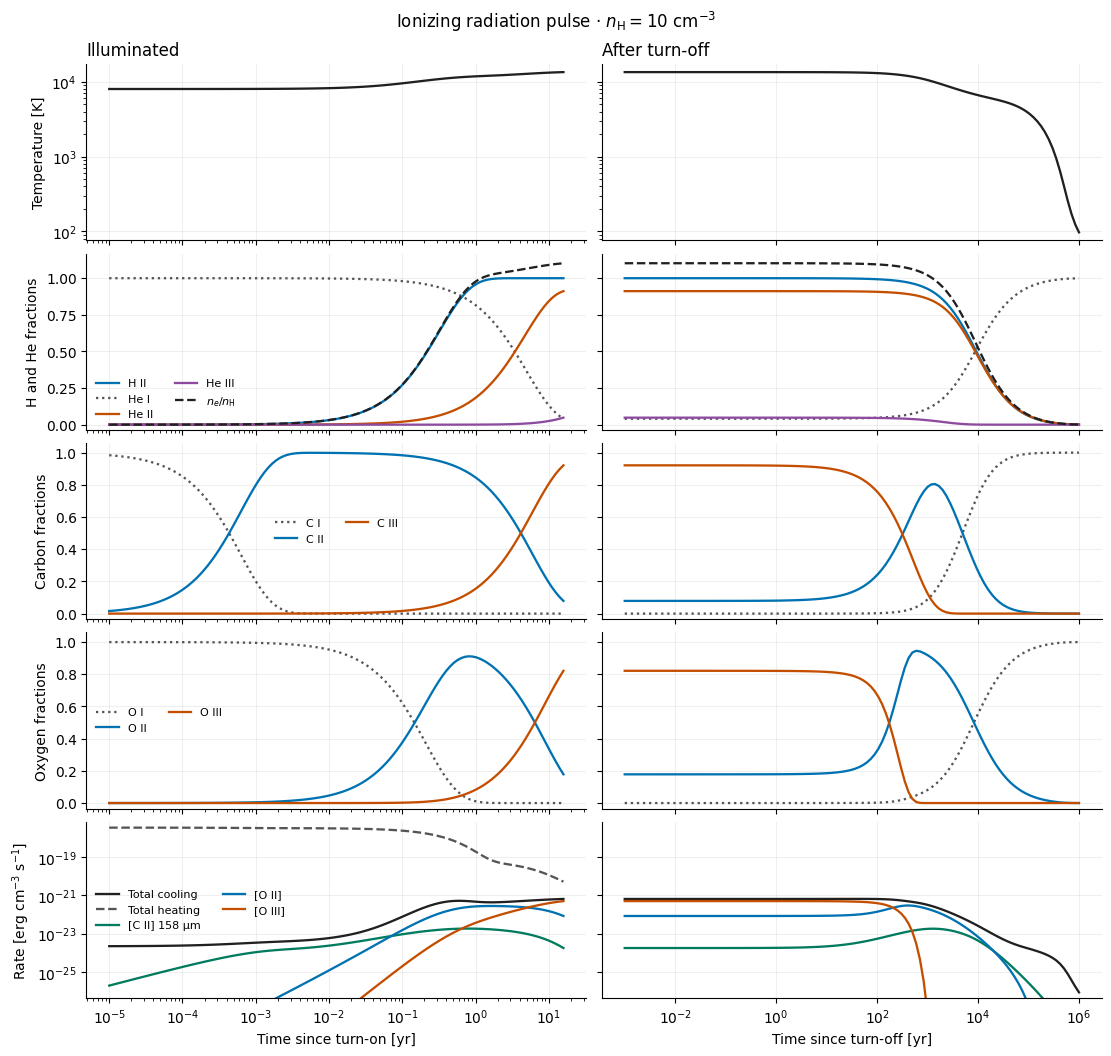

In [2]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_pulse(evolution, "ionizing", "Ionizing radiation pulse", IONIZING_PANELS)
    display(fig)
    plt.close(fig)

## 遠紫外線のオン・オフ

水素核数密度は 100 cm⁻³、初期温度は 100 K です。遠紫外線（$G_0=1000$）を30万年照射した後、3,000万年まで追跡します。照射中の H₂ の解離と昇温、消灯後の H₂ の再形成と冷却を確認します。H₂ の縦軸は水素核分率 $2n(\mathrm{H_2})/n_{\mathrm H}$ です。

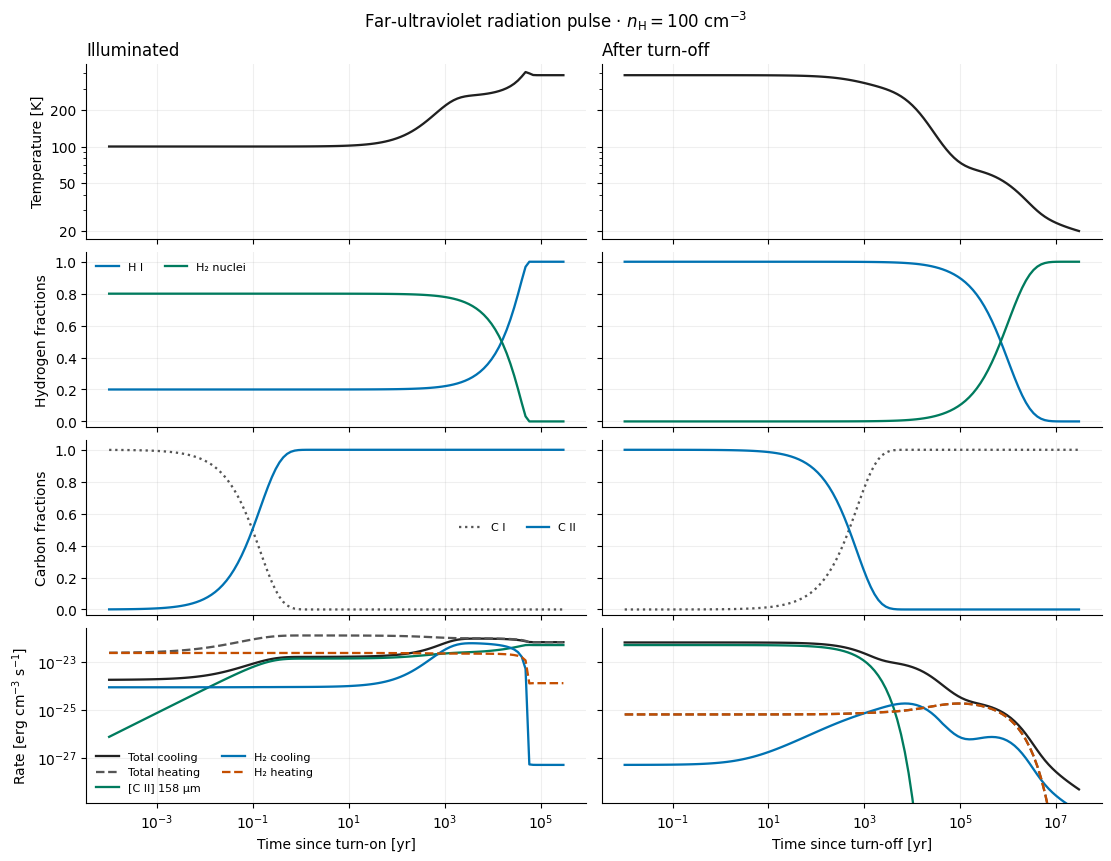

In [3]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_pulse(evolution, "fuv", "Far-ultraviolet radiation pulse", FUV_PANELS)
    display(fig)
    plt.close(fig)

## 同じ温度での平衡・非平衡冷却率

非平衡計算の各時点で、温度・密度・柱密度・照射を固定して化学平衡組成を求め、次の3通りの全冷却率を比較します。

- **非平衡**。時間発展した組成と電子密度から冷却率を計算します。
- **平衡組成＋共通式**。平衡組成を非平衡と同じ冷却式に入れ、組成の履歴の影響を調べます。
- **平衡組成＋既存の平衡モードの式**。平衡モードの冷却式を適用します。酸素イオン輝線の扱いなど、式の違いも含まれます。両計算で金属 CIE テーブルはオフです。

中段の輝線・分子成分は共通式で評価し、下段は非平衡の全冷却率を各平衡値で割った比です。対数軸には正の値を描き、成分図の下限は各図の成分最大値の10⁻¹²です。表には時刻ゼロも含めます。

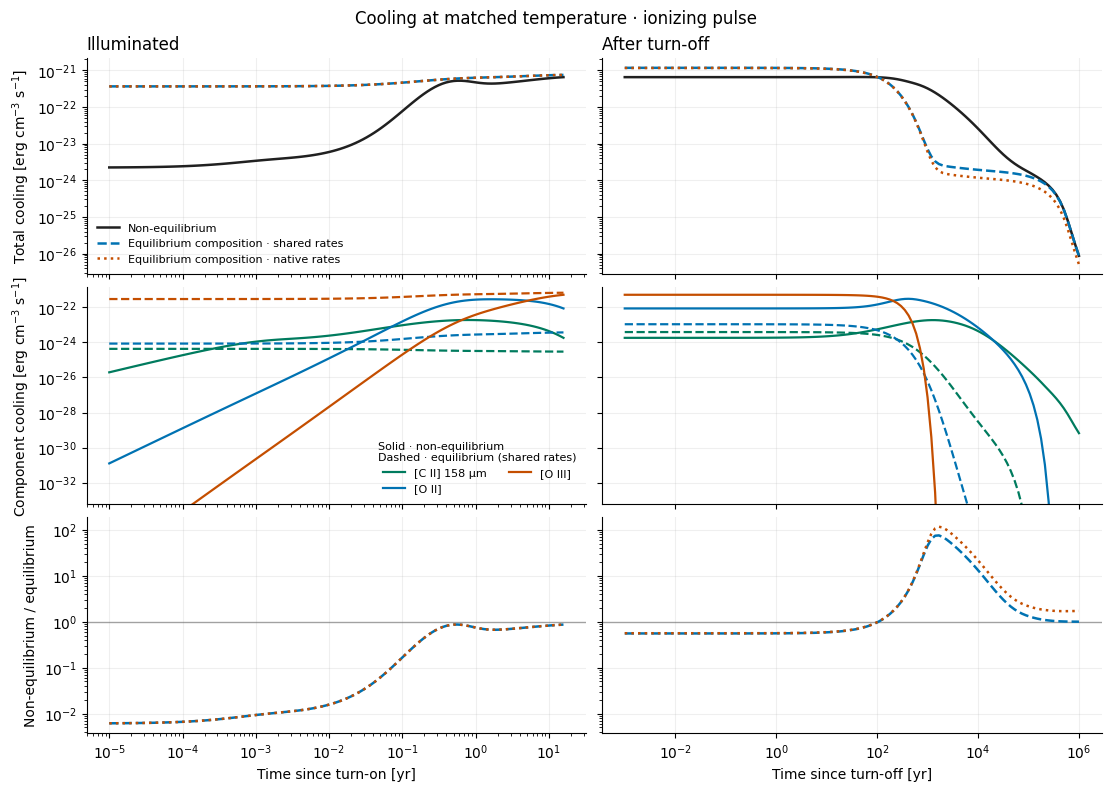

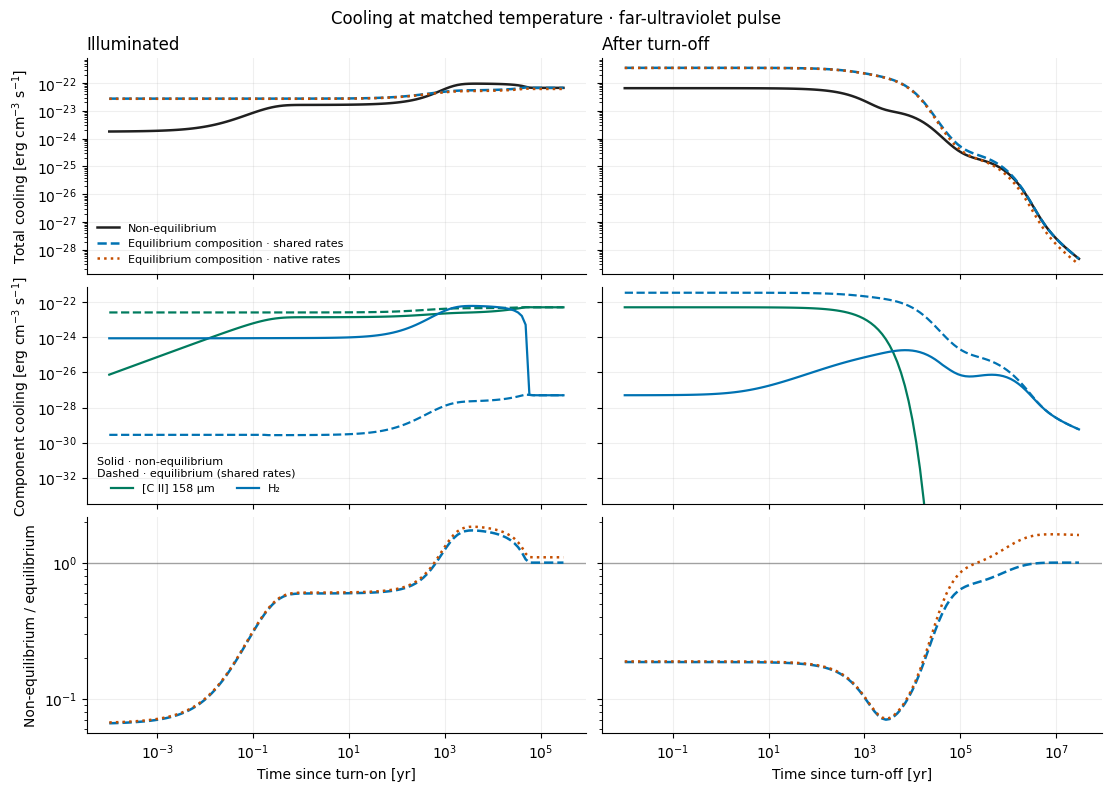

冷却率の単位は erg cm⁻³ s⁻¹ です。

| 照射 | 時点 | 経過年 | 温度 [K] | 非平衡 | 平衡・共通式 | 平衡・既存式 | 非平衡 / 平衡・共通式 |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 恒星電離光 | 点灯直後 | 0 | 8,000.0 | 2.225e-24 | 3.661e-22 | 3.661e-22 | 0.00608 |
| 恒星電離光 | 消灯直後 | 0 | 13,450.8 | 6.543e-22 | 1.175e-21 | 1.163e-21 | 0.557 |
| 恒星電離光 | 消灯後の最大比 | 1,679 | 9,505.5 | 2.121e-22 | 2.780e-24 | 1.797e-24 | 76.3 |
| 恒星電離光 | 消灯フェーズ末 | 1e+06 | 97.1 | 8.727e-27 | 8.684e-27 | 5.066e-27 | 1 |
| 遠紫外線 | 点灯直後 | 0 | 100.0 | 1.781e-24 | 2.756e-23 | 2.716e-23 | 0.0646 |
| 遠紫外線 | 消灯直後 | 0 | 387.4 | 6.547e-23 | 3.530e-22 | 3.494e-22 | 0.185 |
| 遠紫外線 | 消灯フェーズ末 | 3e+07 | 20.1 | 4.802e-29 | 4.802e-29 | 3.008e-29 | 1 |

In [4]:
if "eq_native_L_tot" in evolution.dtype.names:
    scenarios = {"ionizing": "恒星電離光", "fuv": "遠紫外線"}
    table = [
        "冷却率の単位は erg cm⁻³ s⁻¹ です。",
        "",
        "| 照射 | 時点 | 経過年 | 温度 [K] | 非平衡 | 平衡・共通式 | 平衡・既存式 | 非平衡 / 平衡・共通式 |",
        "| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |",
    ]
    for scenario, label in scenarios.items():
        with plt.rc_context(PLOT_STYLE):
            fig = plot_cooling_comparison(evolution, scenario)
            display(fig)
            plt.close(fig)

        rows = evolution[evolution["scenario"] == scenario]
        on = rows[rows["phase"] == "on"]
        off = rows[rows["phase"] == "off"]
        snapshots = [("点灯直後", on[0]), ("消灯直後", off[0])]
        positive = off[(off["L_tot"] > 0) & (off["eq_L_tot"] > 0)]
        if len(positive):
            peak = positive[(positive["L_tot"] / positive["eq_L_tot"]).argmax()]
            if 0 < peak["phase_time_yr"] < off[-1]["phase_time_yr"]:
                snapshots.append(("消灯後の最大比", peak))
        snapshots.append(("消灯フェーズ末", off[-1]))
        for stage, row in snapshots:
            neq, eq, native = (row[key] for key in ("L_tot", "eq_L_tot", "eq_native_L_tot"))
            ratio = f"{neq / eq:.3g}" if neq > 0 and eq > 0 else "—"
            table.append(
                f"| {label} | {stage} | {row['phase_time_yr']:,.4g} | {row['T']:,.1f} | "
                f"{neq:.3e} | {eq:.3e} | {native:.3e} | {ratio} |"
            )
    display(Markdown("\n".join(table)))
else:
    print("冷却率の比較データがありません。既定の data_dir に戻して再実行すると生成できます。")

## エネルギー更新の計算時間

各条件で同じ初期状態から始め、固有の冷却式とソルバーを使う平衡・非平衡のエネルギー更新を比較します。各時間刻みで独立した更新を繰り返し、5バッチの中央値と最小・最大の範囲を示します。初期化や CSV 出力は計測区間から外しています。下段は非平衡を平衡で割った実時間の比です。測定値は実行環境に依存します。

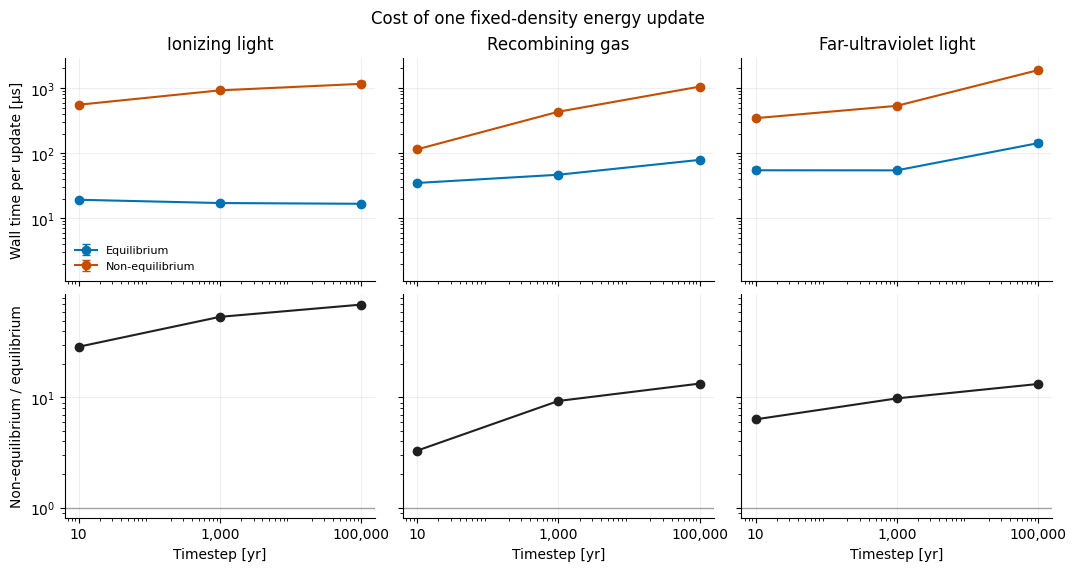

| 条件 | 時間刻み [年] | 平衡 [µs/回] | 非平衡 [µs/回] | 非平衡 / 平衡 |
| --- | ---: | ---: | ---: | ---: |
| 電離光あり | 10 | 19.2 | 554.6 | 28.9 |
| 電離光あり | 1,000 | 17.1 | 922.7 | 54.0 |
| 電離光あり | 100,000 | 16.6 | 1,161.2 | 69.8 |
| 消灯後の再結合 | 10 | 34.8 | 114.4 | 3.3 |
| 消灯後の再結合 | 1,000 | 46.5 | 432.7 | 9.3 |
| 消灯後の再結合 | 100,000 | 78.7 | 1,052.1 | 13.4 |
| 遠紫外線あり | 10 | 54.5 | 344.8 | 6.3 |
| 遠紫外線あり | 1,000 | 54.3 | 533.1 | 9.8 |
| 遠紫外線あり | 100,000 | 142.3 | 1,886.9 | 13.3 |

In [5]:
if benchmark is not None:
    timings = benchmark_timings(benchmark)
    with plt.rc_context(PLOT_STYLE):
        fig = plot_benchmark(timings)
        display(fig)
        plt.close(fig)

    table = [
        "| 条件 | 時間刻み [年] | 平衡 [µs/回] | 非平衡 [µs/回] | 非平衡 / 平衡 |",
        "| --- | ---: | ---: | ---: | ---: |",
    ]
    for (scenario, step), (equilibrium, nonequilibrium) in timings.items():
        eq, neq = equilibrium[0], nonequilibrium[0]
        table.append(f"| {benchmark_labels.get(scenario, scenario)} | {step:,.0f} | {eq:,.1f} | {neq:,.1f} | {neq/eq:.1f} |")
    display(Markdown("\n".join(table)))
else:
    print("計算時間の比較データがありません。既定の data_dir に戻して再実行すると生成できます。")

## 解析解と時間刻みの比較

上段は 1,000 K に固定した純水素の再結合と、case B の解析解 $x_{\mathrm{H II}}=1/(1+t/t_{\mathrm{rec}})$ の比較です。下段は、H・He・C・O を含むセルで同じ時間幅を1ステップと8ステップで積分した場合の差です。点線はテストの許容値です。

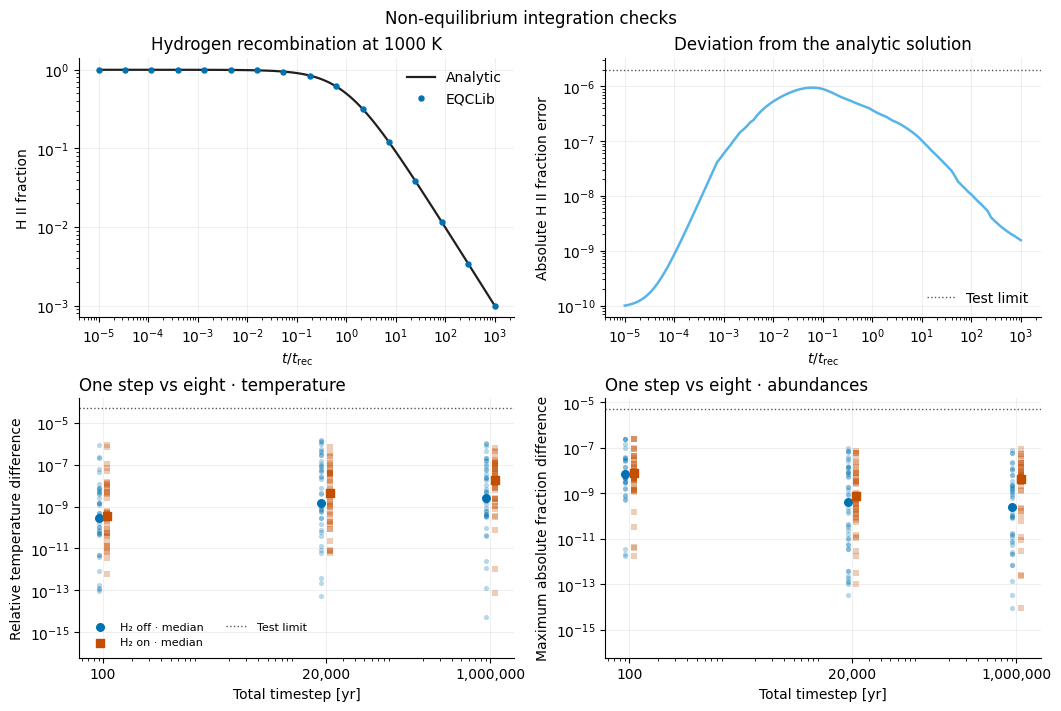

時間刻みの比較は **270 条件**です。

| 比較量 | 最大差 |
| --- | ---: |
| H⁺ 分率と解析解の絶対差 | 9.45e-07 |
| 分割による温度の相対差 | 1.60e-06 |
| 分割による比内部エネルギーの相対差 | 1.60e-06 |
| 分割による化学種分率の絶対差 | 2.45e-07 |

In [6]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_validation(recombination, convergence)
    display(fig)
    plt.close(fig)

comparisons = [
    ("H⁺ 分率と解析解の絶対差", "abs_error", recombination),
    ("分割による温度の相対差", "T_rel_error", convergence),
    ("分割による比内部エネルギーの相対差", "U_rel_error", convergence),
    ("分割による化学種分率の絶対差", "fraction_abs_error", convergence),
]
table = [
    f"時間刻みの比較は **{len(convergence)} 条件**です。",
    "",
    "| 比較量 | 最大差 |",
    "| --- | ---: |",
]
for label, field, values in comparisons:
    table.append(f"| {label} | {values[field].max():.2e} |")
display(Markdown("\n".join(table)))

## 高温ガスの等積冷却

水素核密度 10 cm⁻³、太陽金属量の単一セルに電離ガスの初期組成を与え、外部照射のない状態で冷却します。初期温度は 10⁶ K と 10⁷ K です。CIE（衝突電離平衡）の金属冷却を有効にし、15,000〜25,000 K（図の灰色帯）で [O II]・[O III] と CIE 金属冷却の重みを滑らかに切り替えます。

成分別の冷却率は、ピークの 10⁻⁸ 倍を下限として図示します。表の 25,000 K 到達時刻は、出力点の間で対数温度を線形補間した値です。

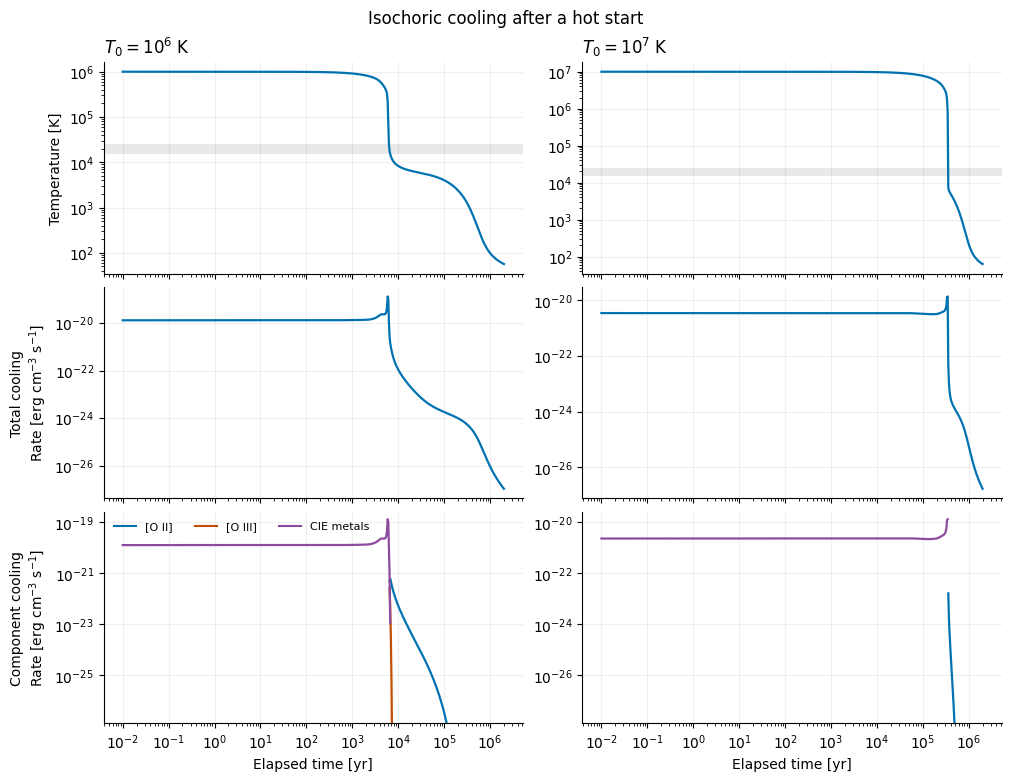

冷却率の単位は erg cm⁻³ s⁻¹ です。

| 初期温度 | 初期の全冷却率 | 初期の CIE / 全冷却 | 25,000 K 到達 [年] | 最終温度 [K] |
| --- | ---: | ---: | ---: | ---: |
| 10⁶ K | 1.300e-20 | 97.1% | 6,266.7 | 56.4 |
| 10⁷ K | 3.463e-21 | 67.1% | 355,094.6 | 62.8 |

In [7]:
def cooling_crossing(rows, threshold):
    if rows[0]["T"] <= threshold:
        return rows[0]["time_yr"]
    for before, after in zip(rows, rows[1:]):
        if after["T"] <= threshold:
            fraction = log(before["T"] / threshold) / log(before["T"] / after["T"])
            return before["time_yr"] + fraction * (after["time_yr"] - before["time_yr"])
    return None


if hot_data is not None:
    hot_history, oxygen_history = hot_data
    with plt.rc_context(PLOT_STYLE):
        fig = plot_hot_cooling(hot_history, compare=False)
        display(fig)
        plt.close(fig)

    table = [
        "冷却率の単位は erg cm⁻³ s⁻¹ です。",
        "",
        "| 初期温度 | 初期の全冷却率 | 初期の CIE / 全冷却 | 25,000 K 到達 [年] | 最終温度 [K] |",
        "| --- | ---: | ---: | ---: | ---: |",
    ]
    for scenario in dict.fromkeys(hot_history["scenario"]):
        rows = sorted(hot_history[hot_history["scenario"] == scenario], key=lambda row: row["time_yr"])
        initial, final = rows[0], rows[-1]
        crossing = cooling_crossing(rows, 25_000)
        crossed = f"{crossing:,.1f}" if crossing is not None else "観測区間外"
        table.append(
            f"| {hot_labels.get(scenario, scenario)} | {initial['L_tot']:.3e} | "
            f"{initial['L_res']/initial['L_tot']:.1%} | {crossed} | {final['T']:,.1f} |"
        )
    display(Markdown("\n".join(table)))
else:
    print(hot_missing)

## 消灯後の酸素輝線

恒星電離光で電離したセルを消灯し、O⁺・O²⁺ の存在比と [O II]・[O III] の冷却率を追跡します。消灯した瞬間は温度と組成が同じなので、輝線冷却は続きます。O²⁺ の再結合によって O⁺ が増えると、[O II] はいったん強まります。この条件での消灯時の温度は15,000 K 未満です。冷却率の図の下限はピークの 10⁻⁸ 倍です。

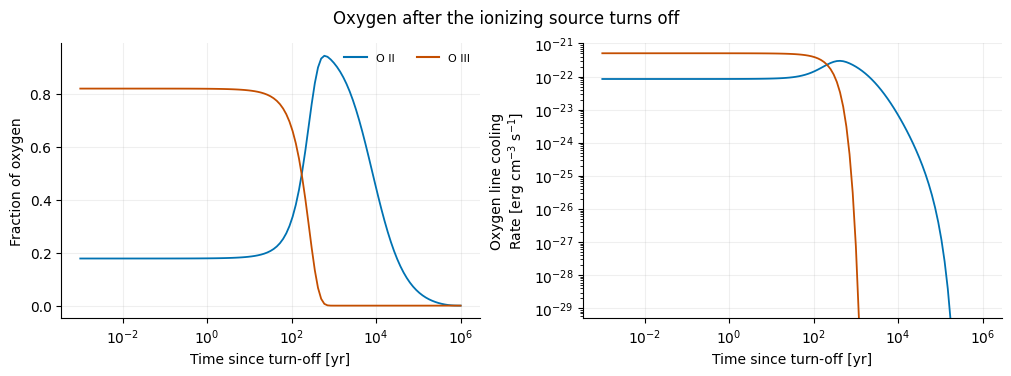

加熱・冷却率の単位は erg cm⁻³ s⁻¹ です。

| 時点 | 消灯後の経過年 | 温度 [K] | 光電離加熱 | [O II] | [O III] |
| --- | ---: | ---: | ---: | ---: | ---: |
| 消灯直前 | 0 | 13,450.8 | 5.260e-21 | 8.453e-23 | 5.062e-22 |
| 消灯直後 | 0 | 13,450.8 | 0.000e+00 | 8.453e-23 | 5.062e-22 |
| [O II] のピーク | 421.7 | 11,914.3 | 0.000e+00 | 2.985e-22 | 3.343e-23 |
| 最後の時刻 | 1e+06 | 97.1 | 0.000e+00 | 1.662e-199 | 0.000e+00 |

In [8]:
if hot_data is not None:
    with plt.rc_context(PLOT_STYLE):
        fig = plot_oxygen_after_switch(oxygen_history, compare=False)
        display(fig)
        plt.close(fig)

    table = [
        "加熱・冷却率の単位は erg cm⁻³ s⁻¹ です。",
        "",
        "| 時点 | 消灯後の経過年 | 温度 [K] | 光電離加熱 | [O II] | [O III] |",
        "| --- | ---: | ---: | ---: | ---: | ---: |",
    ]
    before = oxygen_history[oxygen_history["phase"] == "on"][-1]
    after = sorted(oxygen_history[oxygen_history["phase"] == "off"], key=lambda row: row["time_yr"])
    peak_oii = max(after, key=lambda row: row["L_OII"])
    snapshots = [("消灯直前", before), ("消灯直後", after[0]),
                 ("[O II] のピーク", peak_oii), ("最後の時刻", after[-1])]
    for stage, row in snapshots:
        table.append(
            f"| {stage} | {row['time_yr']:,.4g} | {row['T']:,.1f} | "
            f"{row['H_PI']:.3e} | {row['L_OII']:.3e} | {row['L_OIII']:.3e} |"
        )
    display(Markdown("\n".join(table)))
else:
    print(hot_missing)